## Monte Carlo data viz

In [40]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import importlib
import json
import os

### 20260423 data

In [278]:
"""
load_proximal_promoter.py

Configuration + loader for the proximal_promoter_transc_d_50 experiment.
Merges runs from 20260407 and 20260413 (16 runs each) at each concentration.

Paste this into a notebook cell and run it. Produces:
        on_times, off_times, bound_times, unbound_times,
    pattern_distances, transcription_activity, binding_activity,
    local_concentration   -- each a list of length k (parameters),
                             where each entry is a list of m numpy arrays.
    close_mask            -- boolean version of pattern_distances < 5,
                             same shape.
    params                -- list of parameter values (concentrations).
"""

import importlib
import viz_util.load_transcription as lt
importlib.reload(lt)

# Concentration values shared across both date folders
_concs = [
    0.003, 0.004, 0.005, 0.006, 0.007, 0.008,
    0.009, 0.010, 0.011, 0.012, 0.013, 0.014,
    0.015, 0.016, 0.017, 0.018,
]
# _concs = [0.018]

# _dates = ["data/20260417", "data/20260418", "data/20260420"]
_dates = ["data/20260423"]
# _dates = ["data/20260624"]
# _exp   = "proximal_promoter_transc_long_d_30_c_{:.3f}"
_exp   = "proximal_promoter_transc_d_50_c_{:.3f}"
_runs  = range(1, 17)   # output_cpu1.json ... output_cpu16.json

groups = lt.make_groups([
    (c, [("{}/{}".format(d, _exp.format(c)), _runs) for d in _dates])
    for c in _concs
])

(on_times, off_times, bound_times, unbound_times,
pattern_distances, transcription_activity, binding_activity,
local_concentration, run_ids) = lt.load(groups, n1=0, n=0)

params = np.array(_concs)
total_vol_frac = (params + 0.02)*62**3
sampling_multiplier = 50000 / total_vol_frac

for i, c in enumerate(params):
    for k in range(16):
        on_times[i][k] = on_times[i][k] * sampling_multiplier[i]
        off_times[i][k] = off_times[i][k] * sampling_multiplier[i]
        bound_times[i][k] = bound_times[i][k] * sampling_multiplier[i]
        unbound_times[i][k] = unbound_times[i][k] * sampling_multiplier[i]

close_mask = lt.make_mask(pattern_distances, threshold=5.0)


print("Loaded {} parameter values, {} runs each.".format(
    len(params), len(on_times[0])))

Loaded 16 parameter values, 16 runs each.


#### Pattern distance histogram

Text(0.5, 1.0, 'TF concentration 0.003277777777777778')

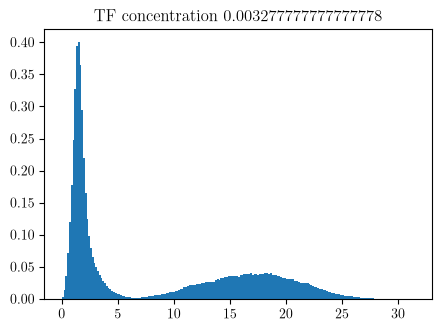

In [279]:
fig, ax = plt.subplots(1,1,figsize=(5,3.5))

tf_conc = np.linspace(5e-4, 8e-3, 28)
k = 10
_=ax.hist(np.concatenate(pattern_distances[k]), bins=200, density=True)
# _=ax.hist(uniform_filter1d(
#     transcription_activity[k][run][start:start+width], size=100* int(sampling_multiplier[k])), 
#     bins=30, density=True)
# ax.set_xlim(0, 1)
xs = np.linspace(0, 50, 200)
a = 5.0
# ax.axvline(5, color="black", lw=1)
# ax.axvline(8, color="black", lw=1)
dist = xs**2 * np.exp(-3*xs**2/(2*(50/a)*a**2))
dist = dist / np.trapezoid(dist, xs)
# ax.plot(xs, dist)
ax.set_title("TF concentration {}".format(tf_conc[k]))

#### Hysteresis Tx, To

In [314]:
import viz_util.hysteresis_times
from viz_util.hysteresis_times import compute_hysteresis_times

# Recompute using hysteresis thresholds
unbound_times, bound_times = compute_hysteresis_times(
            pattern_distances, d_o=8, d_x=3, nparams=16, nruns=16)  # 7 and 6


#### Empirical CDFs

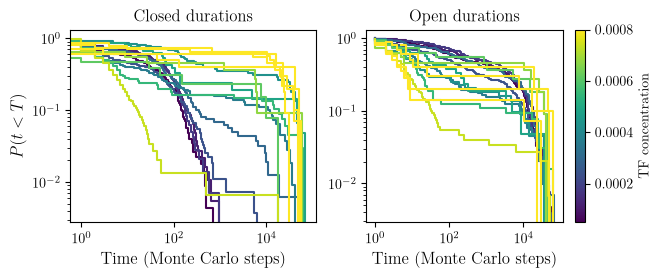

In [315]:
fig, ax = plt.subplots(1,2, figsize=(7,2.5))

# gradient = np.linspace(5e-5, 8e-4, 28)
gradient = np.linspace(0.003, 0.018, 16)
labels = [str(l) for l in gradient]

for k in range(16):
#     ton_sorted = np.sort(np.concatenate(on_times[k]))
#     toff_sorted = np.sort(np.concatenate(off_times[k]))
    
    ton_sorted = np.sort(np.concatenate(bound_times[k]))
    toff_sorted = np.sort(np.concatenate(unbound_times[k]))

    ccdf_on = 1.0 - np.arange(1, len(ton_sorted) + 1) / len(ton_sorted)
    ccdf_off = 1.0 - np.arange(1, len(toff_sorted) + 1) / len(toff_sorted)

    ax[0].step(ton_sorted, ccdf_on, where='post', 
            color=plt.cm.viridis(k/12))
    ax[1].step(toff_sorted, ccdf_off, where='post', 
            color=plt.cm.viridis(k/12))
    
norm = plt.Normalize(vmin=5e-5, vmax=8e-4)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=mpl.cm.viridis)
cbar = plt.colorbar(sm, ax=ax[1], label='TF concentration')

alpha = 0.5
# ax.plot(xs_, alpha*xs_**(-alpha)*2, color="orange", linestyle="dashed",
#         label=r"$C'\alpha x^{-\alpha}, \quad \alpha=1.5$")

xs_ = np.logspace(0, 3.2, 100)
# ax[1].plot(xs_, np.exp(-(xs_)*0.0027)*xs_**-0.07, color="red")

xs_ = np.logspace(0, 4.5, 100)
# ax[0].plot(xs_, 0.055*np.exp(-(xs_)*0.00016) + np.exp(-(xs_)*0.12), color="red")

# ax[0].set_xlim(-500, 20000)
# ax[1].set_xlim(0.8, 8e4)
# ax[1].set_ylim(1e-4, 1.5)
ax[0].set_ylabel("$P(t < T)$", fontsize=12)
ax[0].set_xlabel("Time (Monte Carlo steps)", fontsize=12)
ax[1].set_xlabel("Time (Monte Carlo steps)", fontsize=12)
ax[0].set_title("Closed durations")
ax[1].set_title("Open durations")
# ax[0].set_title("ON times")
# ax[1].set_title("OFF times")

ax[0].set_yscale('log')
ax[0].set_xscale('log')

ax[1].set_yscale('log')
ax[1].set_xscale('log')

#### PDFs

0.008 2656.4311926605506 2503.2038834951454


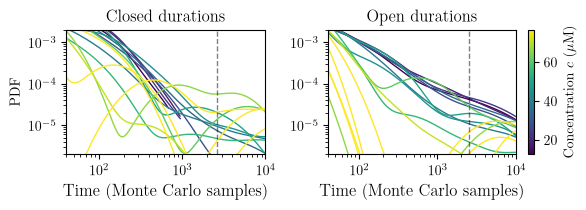

In [316]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

# ---- controls -------------------------------------------------------------
n_grid       = 300     # points on the log-time grid
smooth_sigma = 20       # smoothing width in grid bins (larger = smoother)
per_decade   = False   # True: plot density per log10-decade (flatter on log-x)
                       # False: plot the true pdf f(t) = dF/dt
# ---------------------------------------------------------------------------

gradient = np.linspace(0.003, 0.018, 16)
# vol. frac. <-> concentration conversion factor
theta = 40 * 1e3 / (6e23 * (25 * 1e-9)**3)

norm = plt.Normalize(vmin=gradient[0]*theta, vmax=gradient[-1]*theta)
cmap = mpl.cm.viridis

def cdf_to_pdf(times, n_grid=n_grid, sigma=smooth_sigma):
    """Empirical CDF -> smooth in log-time -> differentiate to a pdf."""
    t = np.sort(np.asarray(times, dtype=float))
    t = t[t > 0]                              # log-time needs t > 0
    if t.size < 2:
        return None, None
    grid = np.logspace(np.log10(t[0]), np.log10(t[-1]), n_grid)
    u    = np.log10(grid)
    F    = np.searchsorted(t, grid, side='right') / t.size   # empirical CDF on grid
    F    = gaussian_filter1d(F, sigma=sigma, mode='nearest') # smooth the CDF
    dF_du = np.gradient(F, u)                                 # density per decade
    pdf   = dF_du if per_decade else dF_du / (grid * np.log(10.0))  # -> f(t)
    return grid, np.clip(pdf, 0, None)

fig, ax = plt.subplots(1, 2, figsize=(6, 2.2), gridspec_kw={"width_ratios": [0.85, 1]})

for k in range(16):
    c = cmap(norm(gradient[k]*theta))

    g, p = cdf_to_pdf(np.concatenate(bound_times[k]))
    if g is not None:
        ax[0].plot(g, p, color=plt.cm.viridis(k/12), lw=1.0)

    g, p = cdf_to_pdf(np.concatenate(unbound_times[k]))
    if g is not None:
        ax[1].plot(g, p, color=plt.cm.viridis(k/12), lw=1.0)

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
plt.colorbar(sm, ax=ax[1], label='Concentration $c$ ($\mu$M)')

for a in ax:
    a.set_xscale('log')
    a.set_yscale('log')
    a.set_xlabel("Time (Monte Carlo samples)", fontsize=12)

ax[0].set_ylabel("density per decade" if per_decade else "PDF")
ax[0].set_title("Closed durations")
ax[0].set_ylim(2e-6, 2e-3)
ax[0].set_xlim(40, 10000)
k = 5
tau_closed = np.mean(np.concatenate(bound_times[k]))
tau_open = np.mean(np.concatenate(unbound_times[k]))
print(gradient[k], tau_closed, tau_open)

ax[0].axvline(tau_closed, lw=1, linestyle="dashed", color="black", alpha=0.5)
ax[1].axvline(tau_open, lw=1, linestyle="dashed", color="black", alpha=0.5)
ax[1].set_title("Open durations")
ax[1].set_ylim(2e-6, 2e-3)
ax[1].set_xlim(40, 10000)

plt.tight_layout()
plt.show()

#### Conditional local concentration (trace)

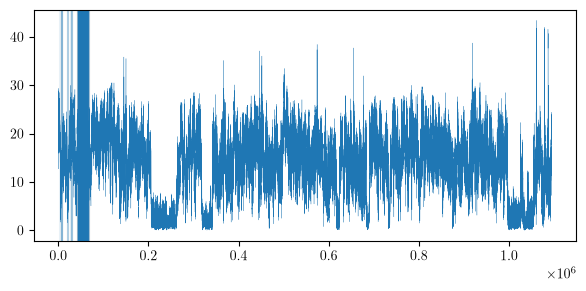

In [ ]:
phi_local_open = np.zeros(16)
phi_local_closed = np.zeros(16)
popen = np.zeros(16)
pclosed = np.zeros(16)

# input: arrays of independent runs for a single phi
def compute_local_conc(all_concs, all_dists, cidx, ridx, thresh=6.5, closed=True):

    local_conc = np.array(all_concs[cidx][ridx])
    pattern_dist = np.array(all_dists[cidx][ridx])

    if closed:
        didx = np.where(pattern_dist < thresh)
    else:
        didx = np.where(pattern_dist >= thresh)

    return didx, local_conc[didx]

for cidx in range(16):
    _local_conc_closed_all_runs = []
    _local_conc_open_all_runs = []
    _mean_transcription_closed_all_runs = []
    _mean_transcription_open_all_runs = []
    _nopen = 0
    _nclosed = 0
    _ntotal = 0

    for run in range(16):
        ic, lcc = compute_local_conc(
            local_concentration, 
            pattern_distances, 
            cidx, run, closed=True
        )
        io, lco = compute_local_conc(
            local_concentration, 
            pattern_distances, 
            cidx, run, closed=False
        )
        _local_conc_closed_all_runs = np.concatenate(
            (_local_conc_closed_all_runs, lcc)
        )
        _local_conc_open_all_runs = np.concatenate(
            (_local_conc_open_all_runs, lco)
        )
        _mean_transcription_closed_all_runs = np.concatenate(
            (_mean_transcription_closed_all_runs, lcc)
                )
        _mean_transcription_open_all_runs = np.concatenate(
            (_mean_transcription_open_all_runs, lco)
        )
        _nclosed += len(ic[0])
        _nopen += len(io[0])
        _ntotal += len(local_concentration[cidx][run])
    
    phi_local_closed[cidx] = np.mean(_local_conc_closed_all_runs)
    phi_local_open[cidx] = np.mean(_local_conc_open_all_runs)
    popen[cidx] = _nopen / _ntotal
    pclosed[cidx] = _nclosed / _ntotal

transcription_closed = np.zeros(16)
transcription_open = np.zeros(16)

for cidx in range(16):
    for _arr, _closed in ((transcription_closed, True), (transcription_open, False)):
        _arr[cidx] = np.mean(np.concatenate([
            compute_local_conc(
                transcription_activity,
                pattern_distances,
                cidx, run, closed=_closed
            )[1]
            for run in range(16)
        ]))

NBOOT = 100
transcription_closed_batch = np.zeros((NBOOT, 16))
transcription_open_batch = np.zeros((NBOOT, 16))

for i in range(NBOOT):
    # run-level (cluster) bootstrap: resample whole runs at every concentration
    runs_ = np.random.randint(0, 16, size=(16, 16))
    for cidx in range(16):
        for _arr, _closed in ((transcription_closed_batch, True), (transcription_open_batch, False)):
            _pooled = np.concatenate([
                compute_local_conc(
                    transcription_activity,
                    pattern_distances,
                    cidx, run, closed=_closed
                )[1]
                for run in runs_[cidx]
            ])
            _arr[i, cidx] = np.mean(_pooled) if len(_pooled) else np.nan

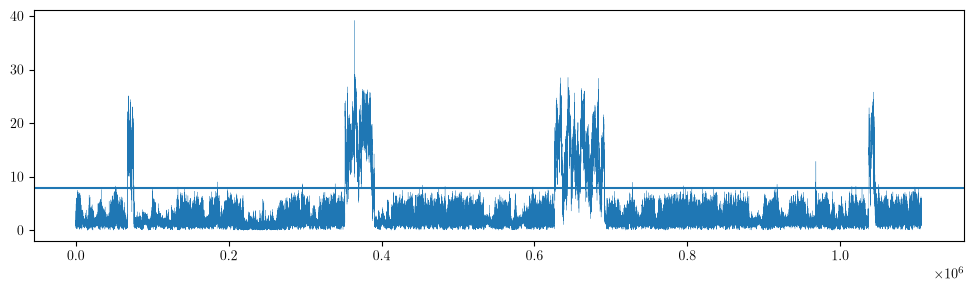

In [310]:
fig, ax = plt.subplots(1,1,figsize=(12, 3))

run = 4
cidx = 6
didx, local_conc = compute_local_conc(
    local_concentration, 
    pattern_distances, 
    cidx, run)
# ax.plot(pattern_distances[cidx][run])
ax.plot(np.concatenate(pattern_distances[cidx]), lw=0.2)
ax.axhline(8)
# ax.axhline(9)

# ax2 = ax.twinx()
# ax2.scatter(didx[0], local_conc, s=5, color="red")

# for k in didx[0]:
#     if k % 100 == 0:
#         ax.axvline(k, alpha=0.1)

#### Splines

In [28]:
# --- polymer Fisher rate: smoothing spline on the local-fit grid -------------
# J[u] = sum_k w_k (u(x_k)-d_k)^2/sum(w) + lam * INT (u'')^2 dx      (same as
# fit_shape, minus every shape penalty).  One solve => y = H d is linear, so
#   LOO:  e_k = (yhat_k - d_k)/(1 - H_kk)            exact, no refits
#   boot: Y_b = H @ (yhat + e*eps_b)                 one matmul
# Endpoints have no score estimate -> w = 0 (extrapolated, see `valid`).

N_SUB, NBOOT, LOGFIT = 6, 400, True          # N_SUB must match fit_c/fit_o
tr  = np.log10 if LOGFIT else (lambda z: z)
inv = (lambda z: 10.0**z) if LOGFIT else (lambda z: z)

def fit_smooth(x, d, w, lam, n_sub=N_SUB):
    x, d, w = np.asarray(x, float), np.asarray(d, float), np.asarray(w, float)
    N = d.size; n = (N - 1)*n_sub + 1
    t = np.linspace(0.0, 1.0, n); h = t[1] - t[0]
    idx = np.arange(N)*n_sub
    E2 = (np.eye(n, k=1)*-2 + np.eye(n, k=2) + np.eye(n))[:-2]
    S = np.zeros((N, n)); S[np.arange(N), idx] = 1.0
    A = S.T @ (w[:, None]*S)/w.sum() + lam*h*(E2.T @ E2)/h**4
    A += 1e-12*np.trace(A)/n*np.eye(n)
    H = np.linalg.solve(A, S.T*w/w.sum())          # y = H d  (cols of w=0 are 0)
    y = H @ np.where(w > 0, d, 0.0)                # so the nan endpoints can't leak
    return dict(x=x[0] + (x[-1] - x[0])*t, y=y, H=H, idx=idx, lam=lam,
                edf=float(np.trace(H[idx])), w=w,
                valid=(t >= (idx[w > 0][0])/(n - 1)) & (t <= (idx[w > 0][-1])/(n - 1)))

def loocv_smooth(x, d, w, lams, n_sub=N_SUB):
    """Closed-form leave-one-out over the weighted points only."""
    m = np.asarray(w) > 0
    out = []
    for lam in lams:
        f = fit_smooth(x, d, w, lam, n_sub)
        e = (f["y"][f["idx"]] - np.where(m, d, 0.0))/(1.0 - np.diag(f["H"][f["idx"]]))
        out.append((np.mean(e[m]**2), lam, np.where(m, e, 0.0)))
    cv = np.array([o[0] for o in out]); k = int(np.argmin(cv))
    return out[k][1], cv, out[k][2]

def boot_smooth(f, d, e_loo, nboot=NBOOT, seed=0):
    """Wild bootstrap: sign-flip the LOO residuals, re-smooth (= one matmul)."""
    rng = np.random.default_rng(seed)
    m = f["w"] > 0
    yhat = np.where(m, f["y"][f["idx"]], 0.0)
    D = yhat + e_loo*rng.choice([-1.0, 1.0], size=(nboot, d.size))
    return D @ f["H"].T

# ---- parameter-free splines along c -----------------------------------------
# Cubic smoothing spline with lambda fixed by closed-form LOOCV (fit_smooth /
# loocv_smooth from the bootstrap cell above), so nothing is tuned by hand.  Fitted in
# log10: rates and variances are both strictly positive.
lams_mc = np.logspace(-10, 1, 23)

def smooth_phi(y, lams=lams_mc, name=""):
    """LOOCV-smoothed y(c) on the refined grid; returns (curve, fit dict, lam)."""
    w = (np.isfinite(y) & (y > 0)).astype(float)
    d = np.log10(np.where(w > 0, y, 1.0))
    lam, _, _ = loocv_smooth(gradient, d, w, lams)
    f = fit_smooth(gradient, d, w, lam)
    if lam in (lams[0], lams[-1]):         # CV ran to the edge: the fit is degenerate
        print(f"WARNING: LOOCV hit the lambda grid edge for {name!r} "
              f"(lam={lam:.1e}, edf={f['edf']:.1f} of {int(w.sum())}) -- "
              f"the data do not pin a smoothing level here.")
    return 10.0**f["y"], f, lam

#### Conditional local concentration (average)

Text(0, 0.5, 'Local Fisher info. rates')

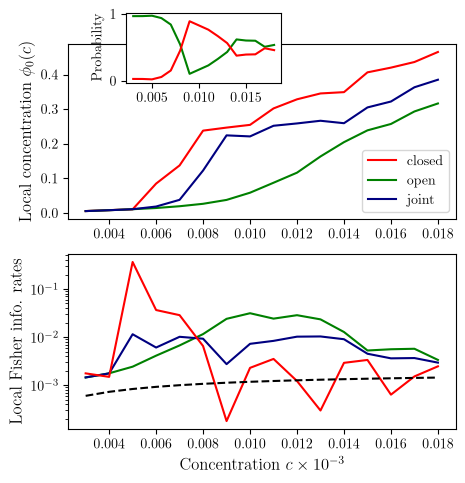

In [30]:
phi_inf = params

fig, ax = plt.subplots(2,1,figsize=(5, 5))

ax[0].plot(phi_inf, phi_local_closed, color="red", label="closed")
ax[0].plot(phi_inf, phi_local_open, color="green", label="open")
ax[0].plot(phi_inf, pclosed*phi_local_closed+popen*phi_local_open, color="navy", label="joint")
ax[0].legend(loc="lower right")
# xticks = np.linspace(2.5, 17.5, 7); 
# # xticks = np.linspace(2.5, 15, 6); 
# ax[0].set_xticks(xticks/1000)
# ax[0].set_xticklabels(xticks)
ax[0].set_ylabel("Local concentration $\phi_0(c)$", fontsize=12)

ins = ax[0].inset_axes(bounds = (0.15, 0.78, 0.4, 0.4))
ins.plot(phi_inf, popen, color="green")
ins.plot(phi_inf, pclosed, color="red")
# insticks = np.array([5.0, 10.0, 15.0])
# ins.set_xticks(insticks/1000)
# ins.set_xticklabels(insticks)
ins.set_ylabel("Probability")

# estimate kinetic constant from mean RNAP OFF time 
mean_toff_rnap = np.mean([np.mean(np.concatenate(off_times[k])) for k in range(16)])
K_D = 7e-3   # chosen near the inflection point
phi_R = 0.02  # fixed RNAP concentration
kb = 1 / (phi_R * mean_toff_rnap)
ku = K_D * kb

tau = 1 / (kb*phi_inf) + 1 / ku
tau_open = 1 / (kb*phi_local_open) + 1 / ku
dphi_local_open = np.gradient(phi_local_open, phi_inf)
phi_local_open_gain = (dphi_local_open * phi_inf / phi_local_open) ** 2

tau_closed = 1 / (kb*phi_local_closed) + 1 / ku
dphi_local_closed = np.gradient(phi_local_closed, phi_inf)
phi_local_closed_gain = (dphi_local_closed * phi_inf / phi_local_closed) ** 2

fisher_rate_open = phi_local_open_gain / tau_open
fisher_rate_closed = phi_local_closed_gain / tau_closed
fisher_rate_base = 1 / tau

fisher_rate_local = pclosed*fisher_rate_closed+popen*fisher_rate_open

ax[1].plot(phi_inf, fisher_rate_open, color="green")
ax[1].plot(phi_inf, fisher_rate_local, color="navy")
ax[1].plot(phi_inf, fisher_rate_closed, color="red")
ax[1].plot(phi_inf, fisher_rate_base, linestyle="dashed", color="black")
ax[1].set_yscale('log')
# ax[1].set_ylim(5e-4, 5)

# ax[1].set_xticks(xticks/1000)
# ax[1].set_xticklabels(xticks)
ax[1].set_xlabel(r"Concentration $c \times 10^{-3}$", fontsize=12)
ax[1].set_ylabel(r"Local Fisher info. rates", fontsize=12)

#### Smoothed local fisher rates

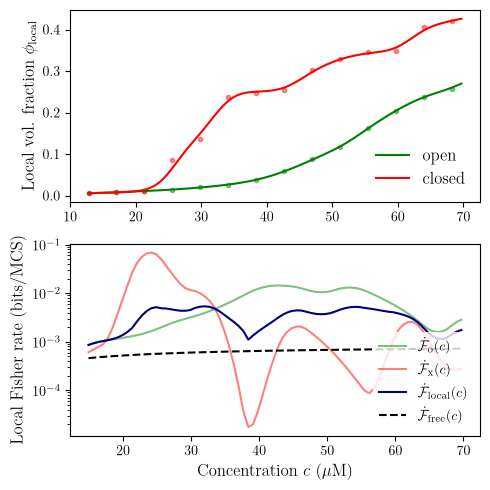

In [33]:
# --- Fisher rate from the fitted curves ------------------------------------
# phi_closed_fitted, dphi_closed_fitted = fit_c["y"], fit_c["dy"]
# phi_open_fitted,   dphi_open_fitted   = fit_o["y"], fit_o["dy"]
phi_closed_fitted, fit_c, _ = smooth_phi(phi_local_closed, lams_mc, "phi_local_closed")
phi_open_fitted, fit_o, _ = smooth_phi(phi_local_open, lams_mc, "phi_local_open")
xf = fit_c["x"]                                     # shared refined c-axis
dphi_closed_fitted = np.gradient(phi_closed_fitted, xf)
dphi_open_fitted = np.gradient(phi_open_fitted, xf)

popen_f, pclosed_f = np.interp(xf, phi_inf, popen), np.interp(xf, phi_inf, pclosed)

mean_toff_rnap = np.mean([np.mean(np.concatenate(off_times[k])) for k in range(16)])
K_D, phi_R = 3e-3, 0.02
kb = 1/(phi_R*mean_toff_rnap)
ku = K_D*kb

tau_open_f   = 1/(kb*phi_open_fitted) + 1/ku
tau_closed_f = 1/(kb*phi_closed_fitted) + 1/ku
gain_open_f   = (dphi_open_fitted*xf/phi_open_fitted)**2
gain_closed_f = (dphi_closed_fitted*xf/phi_closed_fitted)**2
fisher_rate_open_fit   = gain_open_f/tau_open_f
fisher_rate_closed_fit = gain_closed_f/tau_closed_f
fisher_rate_base_f     = 1/(1/(kb*xf) + 1/ku)
fisher_rate_local_fit  = pclosed_f*fisher_rate_closed_fit + popen_f*fisher_rate_open_fit

# --- figure ----------------------------------------------------------------
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})
fig, ax = plt.subplots(2, 1, figsize=(5, 5))
# xticks = np.linspace(2.5, 17.5, 7) * round(theta, 0)

# ax[0].fill_between(xf[:-10]* theta, band_c[0][:-10], band_c[1][:-10], color="red", alpha=0.18, lw=0)
# ax[0].fill_between(xf[:-10]* theta, band_o[0][:-10], band_o[1][:-10], color="green", alpha=0.18, lw=0)
ax[0].plot(phi_inf[:-2]* theta, phi_local_open[:-2], "o", ms=3, color="green", alpha=0.45)
ax[0].plot(phi_inf[:-2]* theta, phi_local_closed[:-2], "o", ms=3, color="red", alpha=0.45)
ax[0].plot(xf[:-10]* theta, phi_open_fitted[:-10], color="green", label="open")
ax[0].plot(xf[:-10]* theta, phi_closed_fitted[:-10], color="red", label="closed")
ax[0].legend(loc="lower right", edgecolor="none", fontsize=12)
ax[0].set_ylabel(r"Local vol. fraction $\phi_{\rm local}$", fontsize=12)

# ax[1].fill_between(xf[3:-10]* theta, qc[0][3:-10], qc[1][3:-10], color="red", alpha=0.1, lw=0)
# ax[1].fill_between(xf[3:-10]* theta, qo[0][3:-10], qo[1][3:-10], color="green", alpha=0.1, lw=0)
# ax[1].fill_between(xf[3:-10]* theta, ql[0][3:-10], ql[1][3:-10], color="navy", alpha=0.3, lw=0)
ax[1].plot(xf[3:-10]* theta, fisher_rate_open_fit[3:-10], color="green", alpha=0.5, label=r"$\dot{\mathcal{F}}_{\rm o}(c)$")
ax[1].plot(xf[3:-10]* theta, fisher_rate_closed_fit[3:-10], color="red", alpha=0.5, label=r"$\dot{\mathcal{F}}_{\rm x}(c)$")
ax[1].plot(xf[3:-10]* theta, fisher_rate_local_fit[3:-10], color="navy", label=r"$\dot{\mathcal{F}}_{\rm local}(c)$")
ax[1].plot(xf[3:-10]* theta, fisher_rate_base_f[3:-10], linestyle="dashed", color="black",
           label=r"$\dot{\mathcal{F}}_{\rm free}(c)$")
ax[1].set_yscale("log"); 
ax[1].legend(edgecolor="none")
# ax[1].set_ylim(3e-4, 1)
# ax[1].set_xticks(xticks/1000); ax[1].set_xticklabels(xticks)
# ax[1].set_xlabel(r"Volume fraction $\phi \times 10^{-3}$", fontsize=12)
ax[1].set_xlabel(r"Concentration $c$  $(\mu$M)", fontsize=12)
ax[1].set_ylabel(r"Local Fisher rate (bits/MCS)", fontsize=12)
plt.tight_layout()

#### Polymer Fisher rate from empirical PDFs

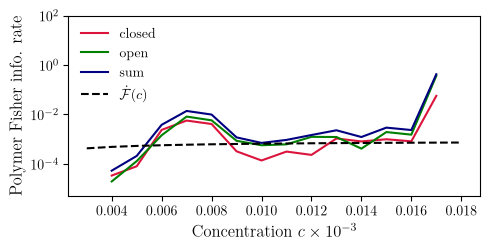

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

# ---- controls -------------------------------------------------------------
n_grid       = 300     # points on each fixed log-time grid
smooth_sigma = 10       # CDF smoothing width in grid bins (as in the pdf cell)
# ---------------------------------------------------------------------------

gradient = np.linspace(0.003, 0.018, 16)          # phi (TF concentration)
K        = len(gradient)
phi_inf = gradient

# pooled series per concentration
series_b = [np.concatenate(bound_times[k])   for k in range(K)]
series_u = [np.concatenate(unbound_times[k]) for k in range(K)]

def make_grid(all_series, n=n_grid):
    """One fixed log-time grid shared by every concentration (so PDFs line up)."""
    lo = min(a[a > 0].min() for a in all_series)
    hi = max(a.max()        for a in all_series)
    return np.logspace(np.log10(lo), np.log10(hi), n)

def pdf_on_grid(times, grid, sigma=smooth_sigma):
    """Smoothed empirical pdf f(t) evaluated on the *fixed* grid."""
    t = np.sort(np.asarray(times, float)); t = t[t > 0]
    u = np.log10(grid)
    F = np.searchsorted(t, grid, side='right') / t.size    # empirical CDF on grid
    F = gaussian_filter1d(F, sigma=sigma, mode='nearest')  # smooth the CDF
    pdf = np.gradient(F, u) / (grid * np.log(10.0))        # f(t) = dF/dt
    return np.clip(pdf, 0.0, None)

def score2_fisher(t, p_lo, p0, p_hi, dphi):
    """∫ P(t|phi) (∂logP/∂phi)² dt  — score-squared Fisher estimator (central 3-pt in phi)."""
    fl    = p0.max() * 1e-10
    lp_lo = np.log(np.maximum(p_lo, fl))
    lp_hi = np.log(np.maximum(p_hi, fl))
    score = (lp_hi - lp_lo) / (2.0 * dphi)                 # ∂logP/∂phi  (central)
    integrand = p0 * score**2                              # = (∂P/∂phi)² / P
    integrand = np.where((p0 > fl) & (p_lo > fl) & (p_hi > fl), integrand, 0.0)
    return np.trapezoid(integrand, t)                          # = +I(phi), always ≥ 0

# fixed grids + PDF stacks (rows = concentration)
grid_b, grid_u = make_grid(series_b), make_grid(series_u)
P_b = np.array([pdf_on_grid(series_b[k], grid_b) for k in range(K)])
P_u = np.array([pdf_on_grid(series_u[k], grid_u) for k in range(K)])

# Fisher information I(phi) = <(∂logP/∂phi)²>, one value per phi (endpoints absent)
dphi = gradient[1] - gradient[0]
I_b  = np.full(K, np.nan)
I_u  = np.full(K, np.nan)
for k in range(1, K - 1):
    I_b[k] = score2_fisher(grid_b, P_b[k-1], P_b[k], P_b[k+1], dphi)
    I_u[k] = score2_fisher(grid_u, P_u[k-1], P_u[k], P_u[k+1], dphi)

# ---- plot -----------------------------------------------------------------
norm = [np.mean(series_b[k]) + np.mean(series_u[k]) for k in range(16)]                          # scalar normalizer (mean dwell)
fig, ax = plt.subplots(figsize=(5, 2.6))
# xticks = np.linspace(2.5, 17.5, 7); 
# xticks = np.linspace(2.5, 15, 6); 
# ax.set_xticks(xticks/1000)
# ax.set_xticklabels(xticks)
ax.plot(gradient, gradient**2*(I_b)/norm,       '-', color='crimson',  label='closed')
ax.plot(gradient, gradient**2*(I_u)/norm,       '-', color='green', label='open')
ax.plot(gradient, gradient**2*(I_b + I_u)/norm, '-', color='navy',     label='sum')
ax.plot(gradient, fisher_rate_base, linestyle="dashed", color="black", label=r"$\dot{\mathcal{F}}(c)$")
ax.axhline(0, color='k', lw=0.6, alpha=0.4)
ax.set_xlabel(r"Concentration  $ c\times 10^{-3}$", fontsize=12)
ax.set_ylabel(r"Polymer Fisher info. rate", fontsize=12)
# ax.set_title("Fisher information of dwell times vs concentration")
ax.legend(edgecolor="none")
ax.set_ylim(5e-6, 1e2)
ax.set_yscale('log')
plt.tight_layout()
plt.show()

#### Polymer fisher rate with bootstrapped error

poly closed  lam=1.0e-05 edf=6.8 sigma_loo=0.6629  (log10 space)
poly open    lam=1.0e-05 edf=6.8 sigma_loo=0.7211  (log10 space)


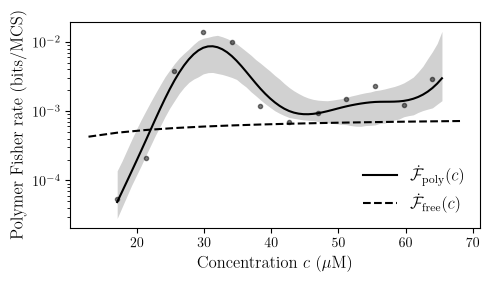

In [ ]:
# ---- data: exactly what the polymer cell plots -----------------------------
poly_c_raw = gradient**2*I_b/norm                  # closed
poly_o_raw = gradient**2*I_u/norm                  # open
w_p = (np.isfinite(poly_c_raw) & np.isfinite(poly_o_raw)
       & (poly_c_raw > 0) & (poly_o_raw > 0)).astype(float)
d_pc = tr(np.where(w_p > 0, poly_c_raw, 1.0))
d_po = tr(np.where(w_p > 0, poly_o_raw, 1.0))

lams_p = np.logspace(-10, 1, 23)
lam_pc, cv_pc, eloo_pc = loocv_smooth(phi_inf, d_pc, w_p, lams_p)
lam_po, cv_po, eloo_po = loocv_smooth(phi_inf, d_po, w_p, lams_p)
fit_pc, fit_po = (fit_smooth(phi_inf, d_pc, w_p, lam_pc),
                  fit_smooth(phi_inf, d_po, w_p, lam_po))
assert np.allclose(fit_pc["x"], fit_c["x"]), "grid mismatch: check N_SUB"

Ypc = inv(boot_smooth(fit_pc, d_pc, eloo_pc, seed=1))
Ypo = inv(boot_smooth(fit_po, d_po, eloo_po, seed=2))

fisher_rate_poly_closed_fit = inv(fit_pc["y"])
fisher_rate_poly_open_fit   = inv(fit_po["y"])
fisher_rate_poly_fit        = fisher_rate_poly_closed_fit + fisher_rate_poly_open_fit
Yp   = Ypc + Ypo                                   # polymer replicates
valid = fit_pc["valid"]                            # False where extrapolated

# ---- the sum: pair replicates (local and polymer are independent) ----------
F_local_b   = pclosed_f*Fc_b + popen_f*Fo_b        # 400 x n, from the local cell
nb          = min(len(F_local_b), len(Yp))
fisher_rate_total_fit = fisher_rate_local_fit + fisher_rate_poly_fit
Ytot        = F_local_b[:nb] + Yp[:nb]
q_poly, q_tot = (np.percentile(Z, [5, 95], axis=0) for Z in (Yp, Ytot))

for nm, f, lam in (("poly closed", fit_pc, lam_pc), ("poly open", fit_po, lam_po)):
    print(f"{nm:12s} lam={lam:.1e} edf={f['edf']:.1f} "
          f"sigma_loo={np.sqrt(np.mean((eloo_pc if f is fit_pc else eloo_po)[w_p>0]**2)):.4f}"
          f"  ({'log10' if LOGFIT else 'linear'} space)")

# ---- plot ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(5, 2.8))
# xticks = np.linspace(2.5, 17.5, 7); 
# ax.set_xticks(xticks/1000)
# ax.set_xticklabels(xticks)
ax.plot(gradient[:-3]*theta, poly_c_raw[:-3] + poly_o_raw[:-3], 'o', ms=3, color='black', alpha=.5)
ax.fill_between(xf[valid][:-10]*theta, q_poly[0, valid][:-10], q_poly[1, valid][:-10], color='black', alpha=.18, lw=0)
ax.plot(xf[valid][:-10]*theta, fisher_rate_poly_fit[valid][:-10], '-', color='black', 
        label=r"$\dot{\mathcal{F}}_{\rm poly}(c)$")
ax.plot(phi_inf[:-2]*theta, fisher_rate_base[:-2], linestyle="dashed", color="black",
        label=r"$\dot{\mathcal{F}}_{\rm free}(c)$")
# ax.plot(xf, fisher_rate_local_fit, '-', color='crimson', label='local')
# ax.fill_between(xf[valid], *q_tot[:, valid], color='k', alpha=.15, lw=0)
# ax.plot(xf[valid], fisher_rate_total_fit[valid], '-', color='k', lw=1.8, label='total')
# ax.set_xlabel(r"Volume fraction  $\phi\times 10^{-3}$", fontsize=12)
ax.set_xlabel(r"Concentration $c$  $(\mu$M)", fontsize=12)
ax.set_ylabel(r"Polymer Fisher rate (bits/MCS)", fontsize=12)
ax.set_yscale('log'); ax.legend(fontsize=12, edgecolor="none")
plt.tight_layout(); plt.show()


In [ ]:
out_dir = "media/figures/20260912"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "fisher_rate_poly.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260912/fisher_rate_poly.pdf


#### Fisher std errors without bootstrap

c-spline edf (of 14 fitted points): closed 8.6  open 6.8  total var 8.6  (total curve = closed + open)
cycle time tau(c) = <t_x> + <t_o>, run bootstrap vs iid SEM (relative):
  0.22/0.11  0.14/0.11  0.37/0.13  0.30/0.12  0.44/0.13  0.22/0.10  0.13/0.07  0.12/0.08  0.16/0.10  0.15/0.09  0.18/0.12  0.33/0.17  0.28/0.15  0.12/0.07  0.16/0.11  0.21/0.10

       c |    M_x        I_x   SE/I  floor  quad/mc |    M_o        I_o   SE/I  floor  quad/mc |       tau  SE/tau       rate   score    +tau
  0.0040 |   1983  3.736e+03  0.313  0.000    2.460 |   1983  3.980e+03  0.027  0.000    1.331 |    4354.8   0.142  1.235e-01   0.152   0.208
  0.0050 |   1587  1.521e+04  0.073  0.000    1.078 |   1587  2.767e+04  0.019  0.000    0.957 |    5121.9   0.367  1.072e+00   0.029   0.368
  0.0060 |   3160  1.777e+05  0.064  0.000    0.958 |   3161  1.087e+05  0.018  0.000    0.952 |    2578.1   0.304  1.031e+01   0.040   0.307
  0.0070 |   4815  1.926e+05  0.015  0.000    0.937 |   4814  2.614e+05  0.033 

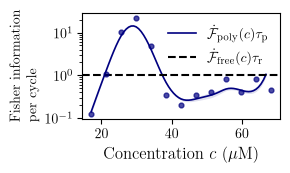

In [ ]:
# ---- Fisher rate without bootstrap: Monte-Carlo score-squared estimator ------
# I(c) = E_c[s(t;c)^2] with the score s = dlog P(t|c)/dc.  Instead of integrating the
# smoothed PDF against the score (score2_fisher, the polymer cell above), average the
# squared score over the ACTUAL dwell samples:
#     G_m = s(t_m; c_k)^2,   I_hat = (1/M) sum_m G_m,   Var(I_hat) = Var_c(G)/M
#     SE  = s_G/sqrt(M),     s_G^2 = sum_m (G_m - I_hat)^2/(M - 1)
# The score is unchanged -- the same central difference on the neighbours (c_k-1, c_k+1)
# at spacing 2 dphi that score2_fisher uses -- so only the integration WEIGHT changes:
# the empirical measure of the sample instead of the gaussian-smoothed PDF, which
# broadens into the large-score tails.  The pay-off is an error bar per concentration,
# with no bootstrap.
# Caveat: the score is itself built from the smoothed PDFs, this concentration's own
# included, so SE is the sampling error of the mean of G at FIXED score; it does not
# carry the score's own estimation error (see the reduced chi^2 at the end).
norm = np.array([np.mean(series_b[k]) + np.mean(series_u[k]) for k in range(16)])          # same scalar time unit as the cells above

# `norm` is the cycle time tau(c) = <t_bound> + <t_unbound>, one empirical mean per
# concentration over a finite, heavy-tailed, run-clustered sample, so it carries a real
# error of its own.  The runs are very unequal in length (a few long dwells dominate the
# pool), which is exactly where the iid SEM var(t)/M goes wrong, so take it from a
# run-level bootstrap: resample the 16 runs with replacement, re-pool, re-average -- the
# same cluster bootstrap used for the transcription means.  The SAME run draw feeds both
# channels, so the bound/unbound correlation within a trace is kept.
# Unlike a single scalar normaliser, tau(c) is estimated separately at every c, so this
# error is independent from point to point: it DOES add c-to-c scatter (it is in the
# chi^2 below) rather than sliding the whole curve rigidly.  Within one c it is common
# to both channels, so it is applied to the total coherently.
_rng         = np.random.default_rng(0)
rel_var_norm = np.zeros(K)                               # (SE_tau/tau)^2, per c
for k in range(K):
    _rb = [np.asarray(r, float) for r in bound_times[k]]
    _ru = [np.asarray(r, float) for r in unbound_times[k]]
    _j  = _rng.integers(0, len(_rb), size=(NBOOT, len(_rb)))
    _mu = np.array([np.concatenate([_rb[i] for i in j]).mean()
                    + np.concatenate([_ru[i] for i in j]).mean() for j in _j])
    rel_var_norm[k] = np.nanvar(_mu, ddof=1)/norm[k]**2

def mc_fisher(series, P, grid):
    """I_hat(c) = <score^2> over the samples, its SE, M, and the floored fraction."""
    I, se = np.full(K, np.nan), np.full(K, np.nan)
    M, fr = np.zeros(K, int), np.full(K, np.nan)
    lg = np.log10(grid)
    for k in range(1, K - 1):             # endpoints: no central difference in c
        t  = series[k][series[k] > 0]
        lt = np.log10(t)
        fl = P[k].max() * 1e-10
        logp = lambda p: np.interp(lt, lg, np.log(np.maximum(p, fl)))
        G    = ((logp(P[k + 1]) - logp(P[k - 1])) / (2 * dphi))**2
        keep = ((np.interp(lt, lg, P[k - 1]) > fl) & (np.interp(lt, lg, P[k]) > fl)
                & (np.interp(lt, lg, P[k + 1]) > fl))
        G    = np.where(keep, G, 0.0)     # score2_fisher zeroes the same region
        I[k], se[k] = G.mean(), G.std(ddof=1) / np.sqrt(G.size)
        M[k], fr[k] = G.size, 1.0 - keep.mean()
    return I, se, M, fr

I_b_mc, I_b_mc_se, n_mc_b, floor_b = mc_fisher(series_b, P_b, grid_b)
I_u_mc, I_u_mc_se, n_mc_u, floor_u = mc_fisher(series_u, P_u, grid_u)

# ---- rates, in the convention of the cells above: c^2 I / norm ---------------
# Two error sources.  (i) The score sampling, one independent draw per channel and per
# concentration: the bound and unbound channels come from disjoint stretches of the same
# trace, so they add in quadrature (dropping the small cycle-to-cycle covariance).
# (ii) The cycle time `norm`, one draw per concentration, shared by the two channels at
# that c: it is applied to the TOTAL coherently rather than once per channel.  It is
# built from the same dwell samples as I_hat, so this drops a (small) I-tau covariance.
fisher_rate_mc_b = gradient**2 * I_b_mc #/ norm
fisher_rate_mc_u = gradient**2 * I_u_mc #/ norm
fisher_rate_mc   = fisher_rate_mc_b + fisher_rate_mc_u

err_score_b = gradient**2 * I_b_mc_se #/ norm             # score sampling only
err_score_u = gradient**2 * I_u_mc_se #/ norm
err_score   = np.hypot(err_score_b, err_score_u)

_rel_norm = np.sqrt(rel_var_norm)                        # relative error of tau(c)
err_fisher_rate_mc_b = np.hypot(err_score_b, fisher_rate_mc_b*_rel_norm)
err_fisher_rate_mc_u = np.hypot(err_score_u, fisher_rate_mc_u*_rel_norm)
err_fisher_rate_mc   = np.hypot(err_score,   fisher_rate_mc  *_rel_norm)

fisher_rate_mc_b_fit, f_b, lam_b = smooth_phi(fisher_rate_mc_b, name="closed rate")
fisher_rate_mc_u_fit, f_u, lam_u = smooth_phi(fisher_rate_mc_u, name="open rate")

# The total curve is the SUM of the two channel fits, as in the bootstrap cell above --
# not a spline through the summed points.  Dividing each point by its own tau(c) leaves
# c-to-c scatter far larger than the error bars, and LOOCV answers that by running to the
# bottom of the lambda grid and interpolating (edf = N, a connect-the-dots "fit" whose
# residuals are identically zero).  Each channel on its own is still smooth enough to fit.
fisher_rate_mc_fit = fisher_rate_mc_b_fit + fisher_rate_mc_u_fit

var_fisher_rate_mc_fit,   f_v,  lam_v  = smooth_phi(err_fisher_rate_mc**2,   name="total var")
var_fisher_rate_mc_b_fit, f_vb, lam_vb = smooth_phi(err_fisher_rate_mc_b**2, name="closed var")
var_fisher_rate_mc_u_fit, f_vu, lam_vu = smooth_phi(err_fisher_rate_mc_u**2, name="open var")
var_score, f_score, lam_score          = smooth_phi(err_score**2, name="score var")

xm = f_b["x"]                              # refined c-axis, shared by every fit
vm = f_b["valid"]                          # False where the spline extrapolates

def logband(y_fit, var_fit):
    """+/- 1 SE band, symmetric in log10 (the fits live in log10)."""
    s = np.sqrt(var_fit) / (y_fit * np.log(10.0))
    return 10.0**(np.log10(y_fit) - s), 10.0**(np.log10(y_fit) + s)

band_mc   = logband(fisher_rate_mc_fit,   var_fisher_rate_mc_fit)
band_mc_b = logband(fisher_rate_mc_b_fit, var_fisher_rate_mc_b_fit)
band_mc_u = logband(fisher_rate_mc_u_fit, var_fisher_rate_mc_u_fit)
band_score = logband(fisher_rate_mc_fit, var_score)

# ---- diagnostics -------------------------------------------------------------
print(f"c-spline edf (of {K-2} fitted points): closed {f_b['edf']:.1f}  "
      f"open {f_u['edf']:.1f}  total var {f_v['edf']:.1f}  (total curve = closed + open)")
print(f"cycle time tau(c) = <t_x> + <t_o>, run bootstrap vs iid SEM (relative):\n  "
      + "  ".join(f"{_rel_norm[k]:.2f}/"
                  f"{np.sqrt(series_b[k].var(ddof=1)/series_b[k].size + series_u[k].var(ddof=1)/series_u[k].size)/norm[k]:.2f}"
                  for k in range(K)) + "\n")
print(f"{'c':>8} | {'M_x':>6} {'I_x':>10} {'SE/I':>6} {'floor':>6} {'quad/mc':>8}"
      f" | {'M_o':>6} {'I_o':>10} {'SE/I':>6} {'floor':>6} {'quad/mc':>8}"
      f" | {'tau':>9} {'SE/tau':>7} {'rate':>10} {'score':>7} {'+tau':>7}")
for k in range(1, K - 1):
    print(f"{gradient[k]:8.4f} |"
          f" {n_mc_b[k]:6d} {I_b_mc[k]:10.3e} {I_b_mc_se[k]/I_b_mc[k]:6.3f}"
          f" {floor_b[k]:6.3f} {I_b[k]/I_b_mc[k]:8.3f} |"
          f" {n_mc_u[k]:6d} {I_u_mc[k]:10.3e} {I_u_mc_se[k]/I_u_mc[k]:6.3f}"
          f" {floor_u[k]:6.3f} {I_u[k]/I_u_mc[k]:8.3f} |"
          f" {norm[k]:9.1f} {_rel_norm[k]:7.3f}"
          f" {fisher_rate_mc[k]:10.3e} {err_score[k]/fisher_rate_mc[k]:7.3f}"
          f" {err_fisher_rate_mc[k]/fisher_rate_mc[k]:7.3f}")

# Both error sources now vary from point to point, so both belong in the residual test.
# What is still missing is the noise in the SCORE: it is built from finite-sample PDFs
# and this estimator holds it fixed, which is what the leftover chi^2 measures.
_m = np.isfinite(fisher_rate_mc) & (fisher_rate_mc > 0)
_r = (np.log10(fisher_rate_mc[_m]) - np.log10(fisher_rate_mc_fit[f_b["idx"]][_m]))
for _lab, _e in (("score only", err_score), ("score + tau", err_fisher_rate_mc)):
    _sig  = _e/(fisher_rate_mc*np.log(10))                       # log10-space sigma
    _chi2 = np.mean((_r/_sig[_m])**2)
    print(f"\nreduced chi^2 of the points about the c-spline, {_lab:>11}: {_chi2:6.1f}"
          f"  => misses a factor ~{np.sqrt(_chi2):.1f} of the c-to-c scatter")

# ---- plot --------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(3, 1.8))

for y, ylo_hi, yfit, c, lab in (
        # (fisher_rate_mc_b, band_mc_b, fisher_rate_mc_b_fit, 'crimson', 'closed'),
        # (fisher_rate_mc_u, band_mc_u, fisher_rate_mc_u_fit, 'green',   'open'),
        (fisher_rate_mc,   band_score,   fisher_rate_mc_fit,   'navy',    r"$\dot{\mathcal{F}}_{\rm poly}(c)\tau_{\rm p}$"),
        ):
    a = 0.3 if lab == 'sum' else 0.12
    ax.fill_between(xm[vm][:-8]*theta, ylo_hi[0][vm][:-8], ylo_hi[1][vm][:-8], color=c, alpha=a, lw=0)
    ax.plot(xm[vm][:-8]*theta, yfit[vm][:-8], '-', color=c, lw=1.2, label=lab)
    ax.scatter(gradient[:-2]*theta, y[:-2], s=12, color=c, alpha=0.7, zorder=3)

# ax.plot(phi_inf*theta, fisher_rate_base, linestyle="dashed", color="black",
#         label=r"$\dot{\mathcal{F}}_{\rm free}(c)$")
ax.set_xlabel(r"Concentration $c$  $(\mu$M)", fontsize=12)
ax.set_ylabel(r"\noindent Fisher information \\ per cycle", fontsize=10)
ax.set_yscale('log')
ax.axhline(1, color="black", linestyle="dashed", label=r"$\dot{\mathcal{F}}_{\rm free}(c)\tau_{\rm r}$", lw=1.5)
ax.legend(edgecolor="none", fontsize=10)
plt.tight_layout()
plt.show()

In [ ]:
out_dir = "media/figures/20260915"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "fisher_per_cycle.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260915/fisher_per_cycle.pdf


#### Decision time

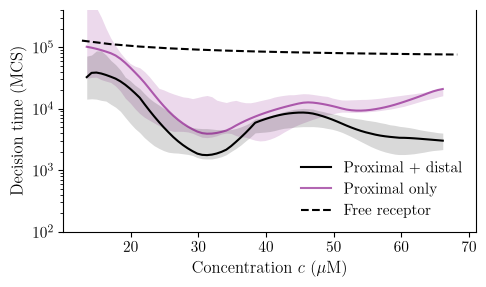

In [ ]:
# ---- plot -----------------------------------------------------------------
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

norm = [np.mean(series_b[k]) + np.mean(series_u[k]) for k in range(16)]                           # scalar normalizer (mean dwell)
fig, ax = plt.subplots(figsize=(5, 3))
# xticks = np.linspace(2.5, 17.5, 7); 
# ax.set_xticks(xticks/1000)
# ax.set_xticklabels(xticks)

fisher_rate_poly = gradient**2*(I_b + I_u)/norm
# ftot = fisher_rate_poly + fisher_rate_local
ftot = fisher_rate_total_fit

dc_c = 0.1
V_tot = 0.5*(dc_c)**2*ftot
V_base = 0.5*(dc_c)**2*fisher_rate_base
V_open = 0.5*(dc_c)**2*fisher_rate_open_fit

Q_tot = 0.5*(dc_c)**2*q_tot
Q_open = 0.5*(dc_c)**2*qo

eps = 0.32
Kdec = np.log((1-eps)/eps)
Tdec_tot = Kdec*np.tanh(Kdec/2)/V_tot
Tdec_base = Kdec*np.tanh(Kdec/2)/V_base
Tdec_open = Kdec*np.tanh(Kdec/2)/V_open
band_poly = Kdec*np.tanh(Kdec/2)/Q_tot
band_open = Kdec*np.tanh(Kdec/2)/Q_open

ax.fill_between(xf[1:][:-15]*theta, band_open[0, 1:][:-15], band_open[1, 1:][:-15], color='purple', alpha=.15, lw=0)
ax.fill_between(xf[1:][:-15]*theta, band_poly[0, 1:][:-15], band_poly[1, 1:][:-15], color='k', alpha=.15, lw=0)
ax.plot(xf[1:][:-15]*theta, Tdec_tot[1:][:-15], '-', color='black',label=r"Proximal + distal")
ax.plot(xf[1:][:-15]*theta, Tdec_open[1:][:-15], '-', color='purple',label=r"Proximal only", alpha=0.6)
ax.plot(phi_inf[:-2]*theta, Tdec_base[:-2], linestyle="dashed", color="black", label=r"Free receptor")
ax.axhline(0, color='k', lw=0.6, alpha=0.4)
# ax.set_xlabel(r"Concentration  $ c\times 10^{-3}$", fontsize=12)
ax.set_ylabel(r"Decision time (MCS)", fontsize=12)
# ax.set_title("Fisher information of dwell times vs concentration")
ax.legend(edgecolor="none", fontsize=11)
ax.set_xlabel(r"Concentration $c$  $(\mu$M)", fontsize=12)
ax.set_ylim(100, 4e5)
ax.set_yscale('log')
plt.tight_layout()
plt.show()

In [ ]:
out_dir = "media/figures/20260912"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "poly_decision_time.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260912/poly_decision_time.pdf


### 20260823 data

In [3]:
import json
import numpy as np
import os

data_path = "data/20260823/proximal_promoter_tranc_d_50_c_sweep_h0_-1.5_chi_-2.5_run{}"
n_conc = 28
_runs = range(1, 8)

keys = [
    "on_times", "off_times", "bound_times", "unbound_times",
    "pattern_distances", "transcription_activity", "binding_activity",
    "local_concentration",
]

loaded = {k: [[] for _ in range(n_conc)] for k in keys}
concentrations = [None] * n_conc

for i in range(n_conc):
    conc_id = i + 1  # keya, 1-indexed to match sim/sweep.jl
    for r in _runs:
        path = os.path.join(data_path.format(r), f"output_cpu{conc_id}.json")

        with open(path) as f:
            res_ = json.load(f)

        res = res_[str(conc_id)]["1"]
        for k in keys:
            loaded[k][i].append(np.array(res[k]))  # run_index = r - 1
        concentrations[i] = res.get("tf_concentration")

on_times = loaded["on_times"]
off_times = loaded["off_times"]
bound_times = loaded["bound_times"]
unbound_times = loaded["unbound_times"]
pattern_distances = loaded["pattern_distances"]
transcription_activity = loaded["transcription_activity"]
binding_activity = loaded["binding_activity"]
local_concentration = loaded["local_concentration"]

print(f"Loaded {n_conc} concentrations ({len(on_times[0])} runs each).")
print("concentrations:", concentrations)

Loaded 28 concentrations (7 runs each).
concentrations: [5e-05, 7.777777777777778e-05, 0.00010555555555555555, 0.00013333333333333334, 0.0001611111111111111, 0.00018888888888888888, 0.00021666666666666666, 0.00024444444444444443, 0.0002722222222222222, 0.0003, 0.0003277777777777778, 0.00035555555555555557, 0.00038333333333333334, 0.0004111111111111111, 0.0004388888888888889, 0.00046666666666666666, 0.0004944444444444445, 0.0005222222222222222, 0.00055, 0.0005777777777777778, 0.0006055555555555556, 0.0006333333333333333, 0.0006611111111111111, 0.0006888888888888888, 0.0007166666666666667, 0.0007444444444444445, 0.0007722222222222222, 0.0008]


#### Pattern distance histogram

Text(0.5, 1.0, 'TF concentration 0.0004944444444444445')

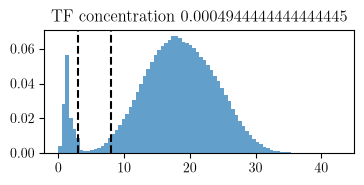

In [167]:
fig, ax = plt.subplots(1,1,figsize=(4,1.6))

k = 16
dists = np.concatenate([np.concatenate(pattern_distances[k]) for k in range(28)])
_=ax.hist(dists, bins=80, density=True, alpha=0.7)
# ax.set_xlim(0, 1)
xs = np.linspace(0, 50, 200)
s = 60
a = 2.0
dist = xs**2 * np.exp(-3*xs**2/(2*s*a**2))
dist = dist / np.trapezoid(dist, xs)
# ax.plot(xs, dist)
ax.axvline(3, color="black", linestyle="dashed")
ax.axvline(8, color="black", linestyle="dashed")
ax.set_title("TF concentration {}".format(concentrations[k]))

In [ ]:
out_dir = "media/figures/20260403"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "distance_histograms.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260403/distance_histograms.pdf


#### Bound/unbound times with hysteresis

In [175]:
import viz_util.hysteresis_times
from viz_util.hysteresis_times import compute_hysteresis_times

# Recompute using hysteresis thresholds
thresh = 3
gap = 0
unbound_times, bound_times = compute_hysteresis_times(
            pattern_distances, d_o=thresh+gap, d_x=thresh, nparams=28, nruns=7)


#### ON/OFF time empirical CDFs

[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 17, 21]

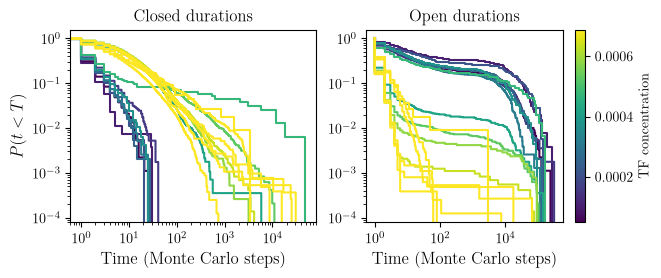

In [176]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

fig, ax = plt.subplots(1,2, figsize=(7,2.5))


gradient = np.linspace(5e-5, 8e-4, 28)
# gradient = np.linspace(0.003, 0.014, 12)
labels = [str(l) for l in gradient]
count = 0
idxs_valid = []
kmax = 23

for k in range(kmax):
    # ton_sorted = np.sort(np.concatenate(on_times[k]))
    # toff_sorted = np.sort(np.concatenate(off_times[k]))
    
    ton_sorted = np.sort(np.concatenate(bound_times[k]))
    toff_sorted = np.sort(np.concatenate(unbound_times[k]))

    if min(len(ton_sorted), len(toff_sorted)) >= 10:
        count += 1
        idxs_valid.append(k)
        ccdf_on = 1.0 - np.arange(1, len(ton_sorted) + 1) / len(ton_sorted)
        ccdf_off = 1.0 - np.arange(1, len(toff_sorted) + 1) / len(toff_sorted)

        ax[0].step(ton_sorted, ccdf_on, where='post', 
                color=plt.cm.viridis(k/12))
        ax[1].step(toff_sorted, ccdf_off, where='post', 
                color=plt.cm.viridis(k/12))
    
norm = plt.Normalize(vmin=gradient[0], vmax=gradient[kmax])
sm = mpl.cm.ScalarMappable(norm=norm, cmap=mpl.cm.viridis)
cbar = plt.colorbar(sm, ax=ax[1], label='TF concentration')

alpha = 0.5
# ax.plot(xs_, alpha*xs_**(-alpha)*2, color="orange", linestyle="dashed",
#         label=r"$C'\alpha x^{-\alpha}, \quad \alpha=1.5$")

xs_ = np.logspace(0, 3.2, 100)
# ax[1].plot(xs_, np.exp(-(xs_)*0.0027)*xs_**-0.07, color="red")

xs_ = np.logspace(0, 4.5, 100)
# ax[0].plot(xs_, 0.055*np.exp(-(xs_)*0.00016) + np.exp(-(xs_)*0.12), color="red")

# ax[0].set_xlim(-500, 20000)
# ax[1].set_xlim(0.8, 8e4)
# ax[1].set_ylim(1e-4, 1.5)
ax[0].set_ylabel("$P(t < T)$", fontsize=12)
ax[0].set_xlabel("Time (Monte Carlo steps)", fontsize=12)
ax[1].set_xlabel("Time (Monte Carlo steps)", fontsize=12)
ax[0].set_title("Closed durations")
ax[1].set_title("Open durations")
# ax[0].set_title("ON times")
# ax[1].set_title("OFF times")

ax[0].set_yscale('log')
ax[0].set_xscale('log')

ax[1].set_yscale('log')
ax[1].set_xscale('log')
idxs_valid

#### ON/OFF time smoothed PDFs

0.0003277777777777778 24.382901554404146 158.1576763485477


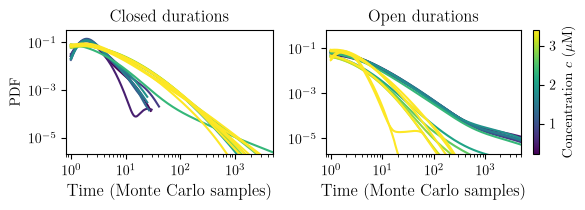

In [177]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

# ---- controls -------------------------------------------------------------
n_grid       = 300     # points on the log-time grid
smooth_sigma = 30       # smoothing width in grid bins (larger = smoother)
per_decade   = False   # True: plot density per log10-decade (flatter on log-x)
                       # False: plot the true pdf f(t) = dF/dt
# ---------------------------------------------------------------------------

# gradient = np.linspace(0.003, 0.018, 16)
theta = 40 * 1e3 / (6e23 * (25 * 1e-9)**3)
norm = plt.Normalize(vmin=5e-5*theta, vmax=8e-4*theta)
cmap = mpl.cm.viridis

def cdf_to_pdf(times, n_grid=n_grid, sigma=smooth_sigma):
    """Empirical CDF -> smooth in log-time -> differentiate to a pdf."""
    t = np.sort(np.asarray(times, dtype=float))
    t = t[t > 0]                              # log-time needs t > 0
    if t.size < 2:
        return None, None
    grid = np.logspace(np.log10(t[0]), np.log10(t[-1]), n_grid)
    u    = np.log10(grid)
    F    = np.searchsorted(t, grid, side='right') / t.size   # empirical CDF on grid
    F    = gaussian_filter1d(F, sigma=sigma, mode='nearest') # smooth the CDF
    dF_du = np.gradient(F, u)                                 # density per decade
    pdf   = dF_du if per_decade else dF_du / (grid * np.log(10.0))  # -> f(t)
    return grid, np.clip(pdf, 0, None)

fig, ax = plt.subplots(1, 2, figsize=(6, 2.2), gridspec_kw={"width_ratios": [0.85, 1]})

for k in idxs_valid:
    c = cmap(norm(gradient[k]*theta))

    g, p = cdf_to_pdf(np.concatenate(bound_times[k]))
    if g is not None:
        ax[0].plot(g, p, color=plt.cm.viridis(k/12), lw=1.5)

    g, p = cdf_to_pdf(np.concatenate(unbound_times[k]))
    if g is not None:
        ax[1].plot(g, p, color=plt.cm.viridis(k/12), lw=1.5)

sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
plt.colorbar(sm, ax=ax[1], label='Concentration $c$ ($\mu$M)')

for a in ax:
    a.set_xscale('log')
    a.set_yscale('log')
    a.set_xlabel("Time (Monte Carlo samples)", fontsize=12)

ax[0].set_ylabel("density per decade" if per_decade else "PDF")
ax[0].set_title("Closed durations")
ax[0].set_ylim(2e-6, None)
ax[0].set_xlim(0.8, 5000)
k = 10
tau_closed = np.mean(np.concatenate(bound_times[k]))
tau_open = np.mean(np.concatenate(unbound_times[k]))
print(gradient[k], tau_closed, tau_open)

# ax[0].axvline(tau_closed, lw=1, linestyle="dashed", color="black", alpha=0.5)
# ax[1].axvline(tau_open, lw=1, linestyle="dashed", color="black", alpha=0.5)
ax[1].set_title("Open durations")
ax[1].set_xlim(0.8, 5000)
ax[1].set_ylim(2e-6, None)

plt.tight_layout()
plt.show()


In [316]:
out_dir = "media/figures/20260908"
os.makedirs(out_dir, exist_ok=True)
out_path = os.path.join(out_dir, "smoothed_PDFs_from_20260823.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260908/smoothed_PDFs_from_20260823.pdf


#### Conditional local concentration (trace)

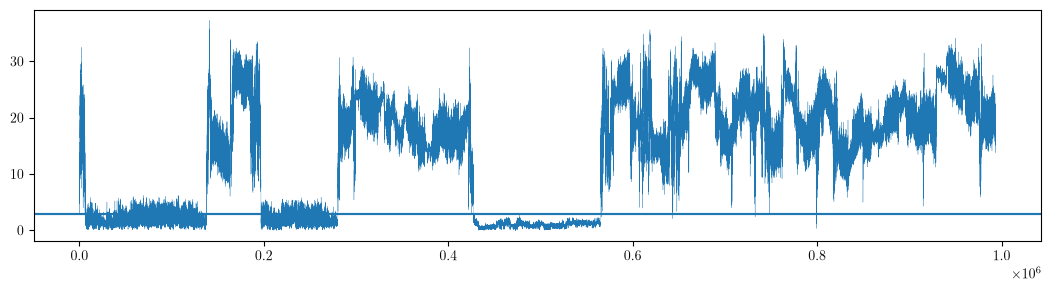

In [225]:
# idxs_valid = range(28)

# input: arrays of independent runs for a single phi
def local_conc_trace(all_concs, all_dists, cidx, ridx, thresh=thresh, closed=True):
    local_conc = np.array(all_concs[cidx][ridx])
    pattern_dist = np.array(all_dists[cidx][ridx])

    if closed:
        didx = np.where(pattern_dist < thresh)
    else:
        didx = np.where(pattern_dist >= thresh)

    return didx, local_conc[didx]

def local_conc_avg(local_concentration, pattern_distances, conc_idxs, run_idxs):
    """run_idxs: one run list for every concentration, or one row per concentration
    (a run-level bootstrap draw)."""
    phi_local_open = np.zeros(len(conc_idxs))
    phi_local_closed = np.zeros(len(conc_idxs))

    for i, cidx in enumerate(conc_idxs):
        _local_conc_closed_all_runs = []
        _local_conc_open_all_runs = []

        for run in (run_idxs[i] if np.ndim(run_idxs) > 1 else run_idxs):
            ic, lcc = local_conc_trace(
                local_concentration, 
                pattern_distances, 
                cidx, run, closed=True
            )
            io, lco = local_conc_trace(
                local_concentration, 
                pattern_distances, 
                cidx, run, closed=False
            )
            _local_conc_closed_all_runs = np.concatenate(
                (_local_conc_closed_all_runs, lcc)
            )
            _local_conc_open_all_runs = np.concatenate(
                (_local_conc_open_all_runs, lco)
            )

        # a run-level draw can miss every closed (or open) frame at this concentration
        phi_local_closed[i] = np.mean(_local_conc_closed_all_runs) if len(_local_conc_closed_all_runs) else np.nan
        phi_local_open[i] = np.mean(_local_conc_open_all_runs) if len(_local_conc_open_all_runs) else np.nan

    return phi_local_closed, phi_local_open

fig, ax = plt.subplots(1,1,figsize=(13, 3))

run = 6
cidx = 11
didx, local_conc = local_conc_trace(
    local_concentration, 
    pattern_distances, 
    cidx, run)
ax.plot(np.concatenate(pattern_distances[cidx]), lw=0.2)

# ax2 = ax.twinx()
# ax2.scatter(didx[0], local_conc, s=5, color="red")
ax.axhline(thresh)
ax.axhline(thresh+gap)

# for k in didx[0]:
#     if k % 100 == 0:
#         ax.axvline(k, alpha=0.1)

In [203]:
np.random.choice([1,2,3], 3)

array([3, 1, 3])

In [115]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

# ---- controls -------------------------------------------------------------
n_grid       = 300     # points on each fixed log-time grid
smooth_sigma = 30      # CDF smoothing width in grid bins (was 50: over-smooths here)
# ---------------------------------------------------------------------------

conc_valid = np.array(concentrations)[idxs_valid]          # == phi_infs[:-2], uniform spacing
K         = len(conc_valid)

# pooled series per concentration, in SECONDS.  escape = closed/bound dwell
# (contact -> x_div), return = open/unbound dwell (x_div -> contact).
series_b = [np.concatenate(bound_times[k]) for k in idxs_valid]
series_u = [np.concatenate(unbound_times[k]) for k in idxs_valid]

N_SUB, NBOOT, LOGFIT = 6, 100, True          # N_SUB must match fit_c/fit_o
K_BATCH  = 7
# assert K_BATCH <= min(s.shape[0] for s in series_b + series_u), "more batches than sojourns"

theta = 40 * 1e3 / (6e23 * (25 * 1e-9)**3)
conc_valid_muM = np.array(conc_valid) * theta

lams_phi = np.logspace(-10, 1, 23)          # smoothing range for the phi-direction fit
tr  = np.log10 if LOGFIT else (lambda z: z)
inv = (lambda z: 10.0**z) if LOGFIT else (lambda z: z)

def fit_smooth(x, d, w, lam, n_sub=N_SUB):
    x, d, w = np.asarray(x, float), np.asarray(d, float), np.asarray(w, float)
    N = d.size; n = (N - 1)*n_sub + 1
    t = np.linspace(0.0, 1.0, n); h = t[1] - t[0]
    idx = np.arange(N)*n_sub
    E2 = (np.eye(n, k=1)*-2 + np.eye(n, k=2) + np.eye(n))[:-2]
    S = np.zeros((N, n)); S[np.arange(N), idx] = 1.0
    A = S.T @ (w[:, None]*S)/w.sum() + lam*h*(E2.T @ E2)/h**4
    A += 1e-12*np.trace(A)/n*np.eye(n)
    H = np.linalg.solve(A, S.T*w/w.sum())          # y = H d  (cols of w=0 are 0)
    y = H @ np.where(w > 0, d, 0.0)                # so the nan endpoints can't leak
    return dict(x=x[0] + (x[-1] - x[0])*t, y=y, H=H, idx=idx, lam=lam,
                edf=float(np.trace(H[idx])), w=w,
                valid=(t >= (idx[w > 0][0])/(n - 1)) & (t <= (idx[w > 0][-1])/(n - 1)))

def loocv_smooth(x, d, w, lams, n_sub=N_SUB):
    """Closed-form leave-one-out over the weighted points only."""
    m = np.asarray(w) > 0
    out = []
    for lam in lams:
        f = fit_smooth(x, d, w, lam, n_sub)
        e = (f["y"][f["idx"]] - np.where(m, d, 0.0))/(1.0 - np.diag(f["H"][f["idx"]]))
        out.append((np.mean(e[m]**2), lam, np.where(m, e, 0.0)))
    cv = np.array([o[0] for o in out]); k = int(np.argmin(cv))
    return out[k][1], cv, out[k][2]

def phi_spline(F):
    """Cubic smoothing spline through F(phi), fitted in log10 space at the LOOCV lambda."""
    w = (np.isfinite(F) & (F > 0)).astype(float)
    d = tr(np.where(w > 0, F, 1.0))
    lam, _, _ = loocv_smooth(conc_valid_muM, d, w, lams_phi)
    f = fit_smooth(conc_valid_muM, d, w, lam)
    return np.where(w > 0, inv(f["y"][f["idx"]]), np.nan), lam, f["edf"]

def make_grid(all_series, n=n_grid):
    """One fixed log-time grid shared by every concentration (so PDFs line up)."""
    lo = min(a[a > 0].min() for a in all_series)
    hi = max(a.max()        for a in all_series)
    return np.logspace(np.log10(lo), np.log10(hi), n)

def pdf_on_grid(times, grid, sigma=smooth_sigma):
    """Smoothed empirical pdf f(t) evaluated on the *fixed* grid."""
    t = np.sort(np.asarray(times, float)); t = t[t > 0]
    u = np.log10(grid)
    F = np.searchsorted(t, grid, side='right') / t.size    # empirical CDF on grid
    F = gaussian_filter1d(F, sigma=sigma, mode='nearest')  # smooth the CDF
    pdf = np.gradient(F, u) / (grid * np.log(10.0))        # f(t) = dF/dt
    return np.clip(pdf, 0.0, None)

def score2_fisher(t, p_lo, p0, p_hi, dphi):
    """∫ P(t|phi) (∂logP/∂phi)² dt  — score-squared Fisher estimator (central 3-pt in phi)."""
    fl    = p0.max() * 1e-10
    lp_lo = np.log(np.maximum(p_lo, fl))
    lp_hi = np.log(np.maximum(p_hi, fl))
    score = (lp_hi - lp_lo) / (2.0 * dphi)                 # ∂logP/∂phi  (central)
    integrand = p0 * score**2                              # = (∂P/∂phi)² / P
    integrand = np.where((p0 > fl) & (p_lo > fl) & (p_hi > fl), integrand, 0.0)
    return np.trapezoid(integrand, t)                      # = +I(phi), always ≥ 0

# fixed log-time grids, shared by the full data and every bootstrap replicate
grid_b, grid_u = make_grid(series_b), make_grid(series_u)

def poly_fisher_rate(sb, su):
    """Polymer Fisher rate from the closed/open duration PDFs, one value per concentration.

    Same estimator as fisher_rate_rouse (viz-rouse): score from the OUTER pair
    (phi_k, phi_k+2) weighted by P(t|phi_k), prefactor phi_k^2, normalised by the cycle
    time <t_closed> + <t_open>.  conc_valid is not uniformly spaced here, so the stencil
    width is read off the grid at each k.  The last two entries are nan -- phi_k+2 is
    off the end of the sweep -- as is any concentration a run draw left with no sojourn.
    """
    nan_row = np.full(n_grid, np.nan)
    Pb = np.array([pdf_on_grid(s, grid_b) if s.size else nan_row for s in sb])
    Pu = np.array([pdf_on_grid(s, grid_u) if s.size else nan_row for s in su])
    tau = np.array([b.mean() + u.mean() if b.size and u.size else np.nan
                    for b, u in zip(sb, su)])
    F = np.full(K, np.nan)
    for k in range(K - 2):                      # last two: phi_k+2 is off the sweep
        dphi_k = (conc_valid_muM[k + 2] - conc_valid_muM[k]) / 2
        I_b = score2_fisher(grid_b, Pb[k], Pb[k], Pb[k + 2], dphi_k)
        I_u = score2_fisher(grid_u, Pu[k], Pu[k], Pu[k + 2], dphi_k)
        F[k] = conc_valid_muM[k]**2*(I_b + I_u)/tau[k]
    return F, tau

In [116]:
### full-data averages
# phi_local = np.array([np.mean(np.concatenate(local_concentration[k])) for k in idxs_valid])

phi_local_c, phi_local_o = local_conc_avg(
    local_concentration, 
    pattern_distances, 
    idxs_valid, 
    range(7)
)

tau_on = np.array([np.mean(np.concatenate(on_times[k])) for k in idxs_valid])
tau_off = np.array([np.mean(np.concatenate(off_times[k])) for k in idxs_valid])
tau_on_smooth, _, _ = phi_spline(tau_on)
tau_off_smooth, _, _ = phi_spline(tau_off)

tau_closed = np.array([np.mean(np.concatenate(bound_times[k])) for k in idxs_valid])
tau_open = np.array([np.mean(np.concatenate(unbound_times[k])) for k in idxs_valid])

tau_closed_smooth, _, _ = phi_spline(tau_closed)
tau_open_smooth, _, _ = phi_spline(tau_open)

phi_local_c_smooth, _, _ = phi_spline(phi_local_c)
phi_local_o_smooth, _, _ = phi_spline(phi_local_o)

p_closed = tau_closed/(tau_closed+tau_open)
p_open = tau_open/(tau_closed+tau_open)
phi_local = phi_local_c*p_closed+phi_local_o*p_open

K_D = 3
ku = 1 / (np.mean(tau_on)*25)   # divide by 180 so that tau_burst_free ranges from 4 to 17 mins
kb = ku / K_D
tau_burst_free = 1 / ku + 1 / (conc_valid_muM * kb)
tau_burst_o = 1 / ku + 1 / (phi_local_o * theta * kb)
tau_burst_c = 1 / ku + 1 / (phi_local_c * theta * kb)

# closed Fisher rate
dphi_local_c = np.gradient(phi_local_c_smooth, conc_valid)
phi_local_c_gain = (dphi_local_c * conc_valid / phi_local_c_smooth) ** 2
fisher_c = phi_local_c_gain / tau_burst_c

# open Fisher rate
dphi_local_o = np.gradient(phi_local_o_smooth, conc_valid)
phi_local_o_gain = (dphi_local_o * conc_valid / phi_local_o_smooth) ** 2
fisher_o = phi_local_o_gain / tau_burst_o

# local Fisher rate
fisher_local = fisher_c*p_closed + fisher_o*p_open
fisher_local_smooth, _, _ = phi_spline(fisher_local)
fisher_c_smooth, _, _ = phi_spline(fisher_c)
fisher_o_smooth, _, _ = phi_spline(fisher_o)

# polymer Fisher rate, from the closed/open duration PDFs
fisher_poly, tau_poly = poly_fisher_rate(series_b, series_u)
fisher_poly_smooth, _, _ = phi_spline(fisher_poly)


### batch averages for bootstrap
phi_local_c_batch = np.zeros((NBOOT, len(idxs_valid)))
phi_local_o_batch = np.zeros((NBOOT, len(idxs_valid)))
phi_local_c_var = np.zeros(len(idxs_valid))
phi_local_o_var = np.zeros(len(idxs_valid))

fisher_c_batch = np.zeros((NBOOT, len(idxs_valid)))
fisher_o_batch = np.zeros((NBOOT, len(idxs_valid)))
fisher_local_batch = np.zeros((NBOOT, len(idxs_valid)))
fisher_poly_batch = np.zeros((NBOOT, len(idxs_valid)))
fisher_c_var = np.zeros(len(idxs_valid))
fisher_o_var = np.zeros(len(idxs_valid))
fisher_local_var = np.zeros(len(idxs_valid))

for i in range(NBOOT):
    # run-level (cluster) bootstrap: resample whole runs, shared by phi and the dwell times
    runs_ = np.random.randint(0, 7, size=(len(idxs_valid), 7))

    phi_local_c_batch[i], phi_local_o_batch[i] = local_conc_avg(
        local_concentration, 
        pattern_distances, 
        idxs_valid, 
        runs_
    )

    tau_open_ = np.zeros(len(idxs_valid))
    tau_closed_ = np.zeros(len(idxs_valid))
    series_b_, series_u_ = [], []

    for ik, k in enumerate(idxs_valid):

        series_c_ = np.concatenate([bound_times[k][r] for r in runs_[ik]])
        series_o_ = np.concatenate([unbound_times[k][r] for r in runs_[ik]])
        series_b_.append(series_c_)
        series_u_.append(series_o_)
        
        tau_closed_[ik] = series_c_.mean() if series_c_.size else np.nan
        tau_open_[ik] = series_o_.mean() if series_o_.size else np.nan

    p_closed_ = tau_closed_/(tau_closed_+tau_open_)
    p_open_ = tau_open_/(tau_closed_+tau_open_)

    phi_local_c_smooth_, _, _ = phi_spline(phi_local_c_batch[i])
    phi_local_o_smooth_, _, _ = phi_spline(phi_local_o_batch[i])

    tau_burst_o_ = 1 / ku + 1 / (phi_local_o_batch[i] * theta * kb)
    tau_burst_c_ = 1 / ku + 1 / (phi_local_c_batch[i] * theta * kb)

    # closed Fisher rate
    dphi_local_c_ = np.gradient(phi_local_c_smooth_, conc_valid)
    phi_local_c_gain_ = (dphi_local_c_ * conc_valid / phi_local_c_smooth_) ** 2
    fisher_c_batch[i] = phi_local_c_gain_ / tau_burst_c_

    # open Fisher rate
    dphi_local_o_ = np.gradient(phi_local_o_smooth_, conc_valid)
    phi_local_o_gain_ = (dphi_local_o_ * conc_valid / phi_local_o_smooth_) ** 2
    fisher_o_batch[i] = phi_local_o_gain_ / tau_burst_o_

    # local Fisher rate
    fisher_local_batch[i] = fisher_c_batch[i]*p_closed_ + fisher_o_batch[i]*p_open_

    # polymer Fisher rate, off the same run draw
    fisher_poly_batch[i], _ = poly_fisher_rate(series_b_, series_u_)


/tmp/ipykernel_11233/968492555.py:34: RuntimeWarning: divide by zero encountered in divide
  tau_burst_c = 1 / ku + 1 / (phi_local_c * theta * kb)
/tmp/ipykernel_11233/968492555.py:103: RuntimeWarning: divide by zero encountered in divide
  tau_burst_c_ = 1 / ku + 1 / (phi_local_c_batch[i] * theta * kb)
/tmp/ipykernel_11233/3758218226.py:73: RuntimeWarning: invalid value encountered in divide
  F = np.searchsorted(t, grid, side='right') / t.size    # empirical CDF on grid


/tmp/ipykernel_11233/2913750808.py:8: RuntimeWarning: Degrees of freedom <= 0 for slice.
  log_fisher_c_var = np.nanvar(pos(fisher_c_batch), axis=0, ddof=1)
/tmp/ipykernel_11233/2913750808.py:10: RuntimeWarning: Degrees of freedom <= 0 for slice.
  log_fisher_local_var = np.nanvar(pos(fisher_local_batch), axis=0, ddof=1)


Text(0.5, 0, 'Concentration $c$ ($\\mu$M)')

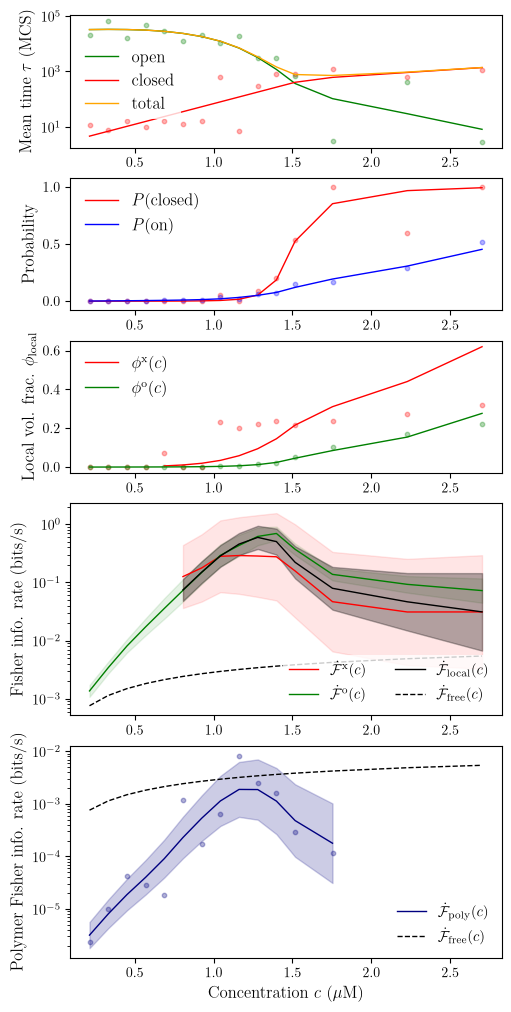

In [117]:
phi_local_c_var = np.nanvar(phi_local_c_batch, axis=0, ddof=1)
phi_local_o_var = np.nanvar(phi_local_o_batch, axis=0, ddof=1)

phi_local_c_var_smooth, _, _ = phi_spline(phi_local_c_var)
phi_local_o_var_smooth, _, _ = phi_spline(phi_local_o_var)

pos = lambda B: np.log10(np.where(B > 0, B, np.nan))   # drop replicates a run draw left undefined
log_fisher_c_var = np.nanvar(pos(fisher_c_batch), axis=0, ddof=1)
log_fisher_o_var = np.nanvar(pos(fisher_o_batch), axis=0, ddof=1)
log_fisher_local_var = np.nanvar(pos(fisher_local_batch), axis=0, ddof=1)
log_fisher_poly_var = np.full(K, np.nan)                    # last two: phi_k+2 off the sweep
log_fisher_poly_var[:K-2] = np.nanvar(pos(fisher_poly_batch[:, :K-2]), axis=0, ddof=1)

log_fisher_c_var_smooth, _, _ = phi_spline(log_fisher_c_var)
log_fisher_o_var_smooth, _, _ = phi_spline(log_fisher_o_var)
log_fisher_local_var_smooth, _, _ = phi_spline(log_fisher_local_var)
log_fisher_poly_var_smooth, _, _ = phi_spline(log_fisher_poly_var)

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
})

fig, ax = plt.subplots(5,1,figsize=(5, 10), 
                       gridspec_kw={"height_ratios": [1, 1, 1, 1.6,1.6]}, 
                       layout="constrained")

# ax[0].plot(conc_valid_muM, tau_on_smooth+tau_off_smooth, color="black", lw=1, label="burst")
# ax[0].plot(conc_valid_muM, tau_burst_free, color="black", lw=1, label="free")
ax[0].plot(conc_valid_muM, tau_open_smooth, color="green", lw=1, label="open")
ax[0].plot(conc_valid_muM, tau_closed_smooth, color="red", lw=1, label="closed")
ax[0].plot(conc_valid_muM, tau_closed_smooth+tau_open_smooth, color="orange", label="total", alpha=1, lw=1)
ax[0].scatter(conc_valid_muM, tau_closed, color="red", s=10, alpha=0.3)
ax[0].scatter(conc_valid_muM, tau_open, color="green", s=10, alpha=0.3)
ax[0].set_yscale('log')
ax[0].set_ylabel(r"Mean time $\tau$ (MCS)", fontsize=12)
ax[0].legend(fontsize=12, edgecolor="none", loc="center left")

ax[1].plot(conc_valid_muM, tau_closed_smooth/(tau_closed_smooth+tau_open_smooth), color="red", lw=1, label=r"$P(\rm closed)$")
ax[1].scatter(conc_valid_muM, tau_closed/(tau_closed+tau_open), color="red", s=10, alpha=0.3)
ax[1].plot(conc_valid_muM, tau_on_smooth/(tau_on_smooth+tau_off_smooth), color="blue", lw=1, label=r"$P(\rm on)$")
ax[1].scatter(conc_valid_muM, tau_on/(tau_on+tau_off), color="blue", s=10, alpha=0.3)
ax[1].set_ylabel(r"Probability", fontsize=12)
ax[1].legend(edgecolor="none", fontsize=12)
ax[1].set_ylim(-0.08, 1.08)

# ax[2].plot(conc_valid_muM, phi_local, color="black")
ax[2].plot(conc_valid_muM, phi_local_c_smooth, color="red", lw=1, label=r"$\phi^{\rm x}(c)$")
ax[2].plot(conc_valid_muM, phi_local_o_smooth, color="green", lw=1, label=r"$\phi^{\rm o}(c)$")
ax[2].scatter(conc_valid_muM, phi_local_c, color="red", s=10, alpha=0.3)
ax[2].scatter(conc_valid_muM, phi_local_o, color="green", s=10, alpha=0.3)
ax[2].set_ylabel(r"Local vol. frac. $\phi_{\rm local}$", fontsize=12)
ax[2].legend(fontsize=12, edgecolor="none")
# ax[2].fill_between(conc_valid_muM, phi_local_c_smooth - np.sqrt(phi_local_c_var),
#                    phi_local_c_smooth + np.sqrt(phi_local_c_var), color="red", alpha=0.2)
# ax[2].fill_between(conc_valid_muM, phi_local_o_smooth - np.sqrt(phi_local_o_var_smooth),
#                    phi_local_o_smooth + np.sqrt(phi_local_o_var_smooth), color="green", alpha=0.2)

ax[3].plot(conc_valid_muM, fisher_c_smooth, color="red", lw=1, label=r"$\dot{\mathcal{F}}^{\rm x}(c)$")
ax[3].plot(conc_valid_muM, fisher_o_smooth, color="green", lw=1, label=r"$\dot{\mathcal{F}}^{\rm o}(c)$")
ax[3].plot(conc_valid_muM, fisher_local_smooth, color="black", lw=1, label=r"$\dot{\mathcal{F}}_{\rm local}(c)$")
ax[3].fill_between(conc_valid_muM, 10**(np.log10(fisher_o_smooth)-np.sqrt(log_fisher_o_var_smooth)), 
                                   10**(np.log10(fisher_o_smooth)+np.sqrt(log_fisher_o_var_smooth)), 
                                   color="green", alpha=0.1)
ax[3].fill_between(conc_valid_muM, 10**(np.log10(fisher_c_smooth)-np.sqrt(log_fisher_c_var_smooth)), 
                                   10**(np.log10(fisher_c_smooth)+np.sqrt(log_fisher_c_var_smooth)), 
                                   color="red", alpha=0.1)
ax[3].fill_between(conc_valid_muM, 10**(np.log10(fisher_local_smooth)-np.sqrt(log_fisher_local_var_smooth)), 
                                   10**(np.log10(fisher_local_smooth)+np.sqrt(log_fisher_local_var_smooth)), 
                                   color="black",alpha=0.3)
ax[3].plot(conc_valid_muM, 1 / tau_burst_free, linestyle="dashed", lw=1, color="black", 
                                label=r"$\dot{\mathcal{F}}_{\rm free}(c)$")
ax[3].set_ylabel(r"Fisher info. rate (bits/s)", fontsize=12)
ax[3].set_yscale('log')
ax[3].legend(fontsize=10.5, edgecolor="none", ncol=2)

ax[4].plot(conc_valid_muM, fisher_poly_smooth, color="navy", lw=1, label=r"$\dot{\mathcal{F}}_{\rm poly}(c)$")
ax[4].scatter(conc_valid_muM, fisher_poly, color="navy", s=10, alpha=0.3)
ax[4].fill_between(conc_valid_muM, 10**(np.log10(fisher_poly_smooth)-np.sqrt(log_fisher_poly_var_smooth)), 
                                   10**(np.log10(fisher_poly_smooth)+np.sqrt(log_fisher_poly_var_smooth)), 
                                   color="navy", alpha=0.2)
ax[4].plot(conc_valid_muM, 1 / tau_burst_free, linestyle="dashed", lw=1, color="black", 
                                label=r"$\dot{\mathcal{F}}_{\rm free}(c)$")
ax[4].set_ylabel(r"Polymer Fisher info. rate (bits/s)", fontsize=12)
ax[4].set_yscale('log')
ax[4].legend(fontsize=10.5, edgecolor="none")
ax[4].set_xlabel("Concentration $c$ ($\mu$M)", fontsize=12)

In [75]:
tau_burst_free

array([52.60143428, 35.06242611, 26.75447487, 21.90816998, 18.73300471,
       16.49171158, 14.82510899, 13.53727972, 12.51227275, 11.67708188,
       10.98344879, 10.39819587,  9.46495473,  8.19415828,  7.36925532])

In [77]:
(tau_closed+tau_open)/tau_burst_free

array([ 21.09180663,  57.95242355,  48.98142073, 103.98764905,
        57.50300097,  36.62704308,  60.29556284,  83.39060687,
       185.3699694 ,  68.23712723, 141.5076153 ,  55.98097631,
        57.54642258,  44.15993872,  37.14431635])

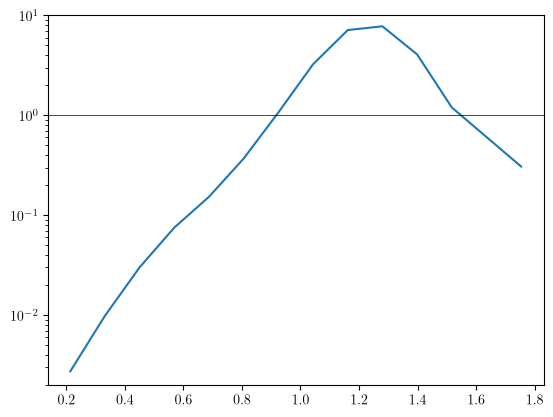

In [73]:
fig, ax = plt.subplots(1,1)

ax.set_ylim(2e-3, 10)
ax.plot(conc_valid_muM, fisher_poly_smooth * (tau_open_smooth+tau_closed_smooth))
ax.axhline(1, linestyle="solid", color="black", lw=0.5)
ax.set_yscale('log')

In [392]:
out_dir = "media/figures/20260908"
os.makedirs(out_dir, exist_ok=True) 
out_path = os.path.join(out_dir, "fisher_local_from_20260823.pdf")
fig.savefig(out_path, format="pdf", bbox_inches="tight")
print("Saved figure to", out_path)

Saved figure to media/figures/20260908/fisher_local_from_20260823.pdf
